# 04 – Hintergrund abziehen und Helligkeit strecken

**Was:** Für jeden Filter den Himmelshintergrund und das Rauschen in leeren Regionen messen, Schwarz- und Weißpunkt festlegen und eine nichtlineare Streckung wählen. Ergebnis: sechs Graustufenbilder mit Werten 0–1, bereit für die Farbe.

**Warum:** Der Dynamikumfang liegt bei ≈ 140 000 : 1 (Etappe 2), ein Bildschirm zeigt 256 Stufen pro Farbe. Ohne Streckung sehen wir nur den Zentralstern; mit schlecht gewähltem Schwarzpunkt sehen wir vor allem Rauschen.

**Mikroskopie-Analogie:** Fiji *Brightness/Contrast* (Min/Max) + eine nichtlineare LUT (Gamma). Der Hintergrund wird wie bei einer Hintergrund-ROI neben der Zelle bestimmt.

**Ergebnis:** Sechs gestreckte Graustufenbilder (0–1) in `data/ngc3132_nircam_stretched/`, Parameter in `params/ngc3132_stretch.json`. Hintergrund aus 6 leeren, über das Bild verteilten Boxen; Streckung asinh (a = 0,05), Weißpunkt 99,9 %, Schwarzpunkt pro Filter angepasst. Gesättigte Sternkerne werden weiß statt schwarz dargestellt.

In [14]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.ndimage import distance_transform_edt, binary_fill_holes
from astropy.io import fits
from astropy.stats import sigma_clipped_stats

IN_DIR = Path("..") / "data" / "ngc3132_nircam_reproj_lw"
OUT_DIR = Path("..") / "data" / "ngc3132_nircam_stretched"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PARAM_FILE = Path("..") / "params" / "ngc3132_stretch.json"   # small, goes into git
PARAM_FILE.parent.mkdir(exist_ok=True)

BANDS = ["F090W", "F187N", "F212N", "F356W", "F405N", "F470N"]
imgs, header = {}, None
for b in BANDS:
    with fits.open(IN_DIR / f"ngc3132_{b.lower()}_reproj_lw.fits") as hdul:
        imgs[b] = hdul[0].data.astype(np.float32)
        header = header or hdul[0].header

# Saturated star cores are NaN *inside* the image (pipeline flags them as unusable).
# NaN regions not connected to the border = holes -> fill with the band's brightest value
# (saturated = "brighter than measurable" -> white after stretching). Cosmetic, documented.
filled = {}
for b in BANDS:
    finite = np.isfinite(imgs[b])
    holes = binary_fill_holes(finite) & ~finite
    imgs[b][holes] = np.nanmax(imgs[b])
    filled[b] = int(holes.sum())
    print(f"{b}: {filled[b]:4d} hole pixels (saturated cores) filled")

# Pixels valid in ALL bands – only these can get a proper colour later.
valid = np.logical_and.reduce([np.isfinite(imgs[b]) for b in BANDS])
print(f"valid in all bands: {100 * valid.mean():.1f} % of the grid")

F090W:  396 hole pixels (saturated cores) filled
F187N:  257 hole pixels (saturated cores) filled
F212N:  209 hole pixels (saturated cores) filled
F356W:  509 hole pixels (saturated cores) filled
F405N:  245 hole pixels (saturated cores) filled
F470N:  162 hole pixels (saturated cores) filled
valid in all bands: 55.3 % of the grid


## 1. Leere Himmelsregionen finden

Statt den Hintergrund über das ganze Bild zu schätzen (dort steckt Nebellicht drin, siehe Etappe 2), suchen wir Boxen, die **in allen Filtern** möglichst dunkel sind:

1. Kandidaten-Boxen (150 × 150 px) auf einem Gitter, nur vollständig im gültigen Bereich und mit Abstand zum Rand (dort ist laut WHT-Karte weniger belichtet).
2. Für jede Box: Median pro Filter, geteilt durch einen hellen Referenzwert des Filters (99,9-%-Perzentil), dann über die Filter summiert → kleiner Wert = überall dunkel.
3. Die dunkelsten, sich nicht überlappenden Boxen werden gewählt und **auf der Karte gezeigt**.

**Bitte prüfen:** Liegen die Boxen wirklich außerhalb des Nebels, auch der schwachen H₂-Filamente in F212N? Sonst `EDGE_MARGIN`, `BOX` oder `N_BOXES` anpassen oder Boxen von Hand festlegen.

594 candidate boxes, best score 0.0319
  box 0: y= 2025 x=  525  score=0.0319
  box 1: y= 1500 x=  600  score=0.0346
  box 2: y=  825 x=  825  score=0.0370
  box 3: y= 1125 x= 2625  score=0.0380
  box 4: y= 2250 x=  975  score=0.0413
  box 5: y=  375 x= 1050  score=0.0415


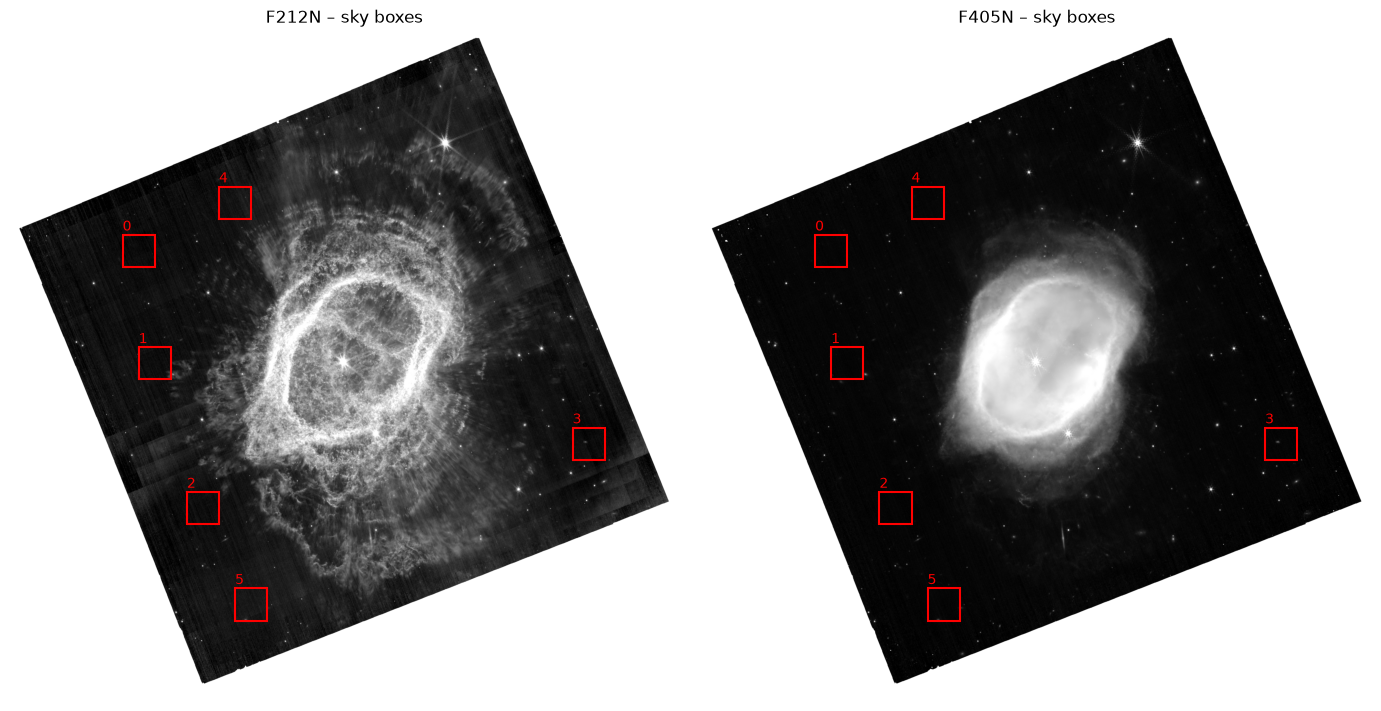

In [15]:
BOX = 150          # box size in px (150 px ≈ 9.5″)
EDGE_MARGIN = 150  # keep away from the low-weight edges
N_BOXES = 6

inner = distance_transform_edt(valid) > EDGE_MARGIN   # distance to nearest invalid pixel
p999 = {b: np.percentile(imgs[b][valid], 99.9) for b in BANDS}

cands = []
for y in range(0, valid.shape[0] - BOX, BOX // 2):
    for x in range(0, valid.shape[1] - BOX, BOX // 2):
        if not inner[y:y + BOX, x:x + BOX].all():
            continue
        score = sum(np.median(imgs[b][y:y + BOX, x:x + BOX]) / p999[b] for b in BANDS)
        cands.append((score, y, x))
cands.sort()

MIN_SEP = 500   # min. distance between box centres in px (≈ 30″) → spread over the field

boxes, box_scores = [], []
for score, y, x in cands:
    if all(np.hypot(y - yy, x - xx) >= MIN_SEP for yy, xx in boxes):
        boxes.append((y, x))
        box_scores.append(score)
    if len(boxes) == N_BOXES:
        break
print(f"{len(cands)} candidate boxes, best score {cands[0][0]:.4f}")
for i, ((y, x), s) in enumerate(zip(boxes, box_scores)):
    print(f"  box {i}: y={y:5d} x={x:5d}  score={s:.4f}")

def preview(img, lo=1, hi=99.5, a=0.05):
    v = img[valid]
    l, h = np.percentile(v, [lo, hi])
    y = np.clip((img - l) / (h - l), 0, 1)
    return np.where(valid, np.arcsinh(y / a) / np.arcsinh(1 / a), np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, b in zip(axes, ["F212N", "F405N"]):
    ax.imshow(preview(imgs[b]), origin="lower", cmap="gray")
    for i, (y, x) in enumerate(boxes):
        ax.add_patch(Rectangle((x, y), BOX, BOX, fill=False, ec="red", lw=1.5))
        ax.text(x, y + BOX + 20, str(i), color="red")
    ax.set_title(f"{b} – sky boxes")
    ax.axis("off")
plt.tight_layout()

## 2. Hintergrund und Rauschen pro Filter

In jeder Box robuste Statistik (Sigma-Clipping wirft einzelne Sterne und Hotpixel raus). Pro Filter dann der Median über die Boxen.

Die Streuung zwischen den Boxen (`bkg spread`) ist ein Maß dafür, wie *ungleichmäßig* der Hintergrund ist. Ist sie groß gegenüber dem Rauschen (wie vermutlich bei F212N mit seinen Helligkeitssprüngen), reicht ein einzelner abgezogener Wert nicht für ein perfekt flaches Bild. Das notieren wir als bekannte Einschränkung.

In [17]:
stats = {}
print(f"{'band':<6}{'bkg':>9}{'noise':>9}{'bkg spread':>12}{'spread/noise':>14}")
for b in BANDS:
    meds, stds = [], []
    for y, x in boxes:
        _, med, sd = sigma_clipped_stats(imgs[b][y:y + BOX, x:x + BOX], sigma=3.0, maxiters=5)
        meds.append(med); stds.append(sd)
    bkg, noise, spread = np.median(meds), np.median(stds), np.ptp(meds)
    stats[b] = dict(bkg=float(bkg), noise=float(noise), spread=float(spread))
    print(f"{b:<6}{bkg:9.4f}{noise:9.4f}{spread:12.4f}{spread / noise:14.2f}")

band        bkg    noise  bkg spread  spread/noise
F090W    0.2067   0.0184      0.0274          1.49
F187N    0.0301   0.1099      0.4062          3.69
F212N   -0.0126   0.1057      0.2774          2.62
F356W    0.1123   0.0041      0.0142          3.49
F405N    0.1166   0.0360      0.0354          0.98
F470N    0.4152   0.0573      0.1292          2.25


## 3. Streckfunktionen im Vergleich (F212N)

Alle vier Varianten nutzen denselben Schwarz- und Weißpunkt; nur die Kurve dazwischen ändert sich:

| Streckung | Formel (x = 0…1) | Verhalten |
|---|---|---|
| linear | x | helle Bereiche dominieren, schwacher Nebel unsichtbar |
| Wurzel | √x | wie Gamma 0,5 in Fiji, moderat |
| log | log(1 + c·x) / log(1 + c) | stark, hebt aber auch das Rauschen sehr an |
| **asinh** | asinh(x/a) / asinh(1/a) | nahe 0 **linear** (Rauschen bleibt ruhig), bei hellen Werten **logarithmisch** (Stern wird gebändigt) |

asinh ist in der Astronomie für Farbbilder verbreitet, genau wegen dieses Übergangs. Der Parameter `a` legt fest, wo der Übergang liegt: kleiner `a` → stärkere Streckung.

**Schwarzpunkt:** `bkg − k·noise` statt genau `bkg`. Mit k ≈ 1–2 bleibt das Rauschen als feine Körnung sichtbar, statt als harte schwarze Flecken abgeschnitten zu werden.
**Weißpunkt:** ein hohes Perzentil der gültigen Pixel. Der Zentralstern und helle Sterne dürfen ausbrennen.

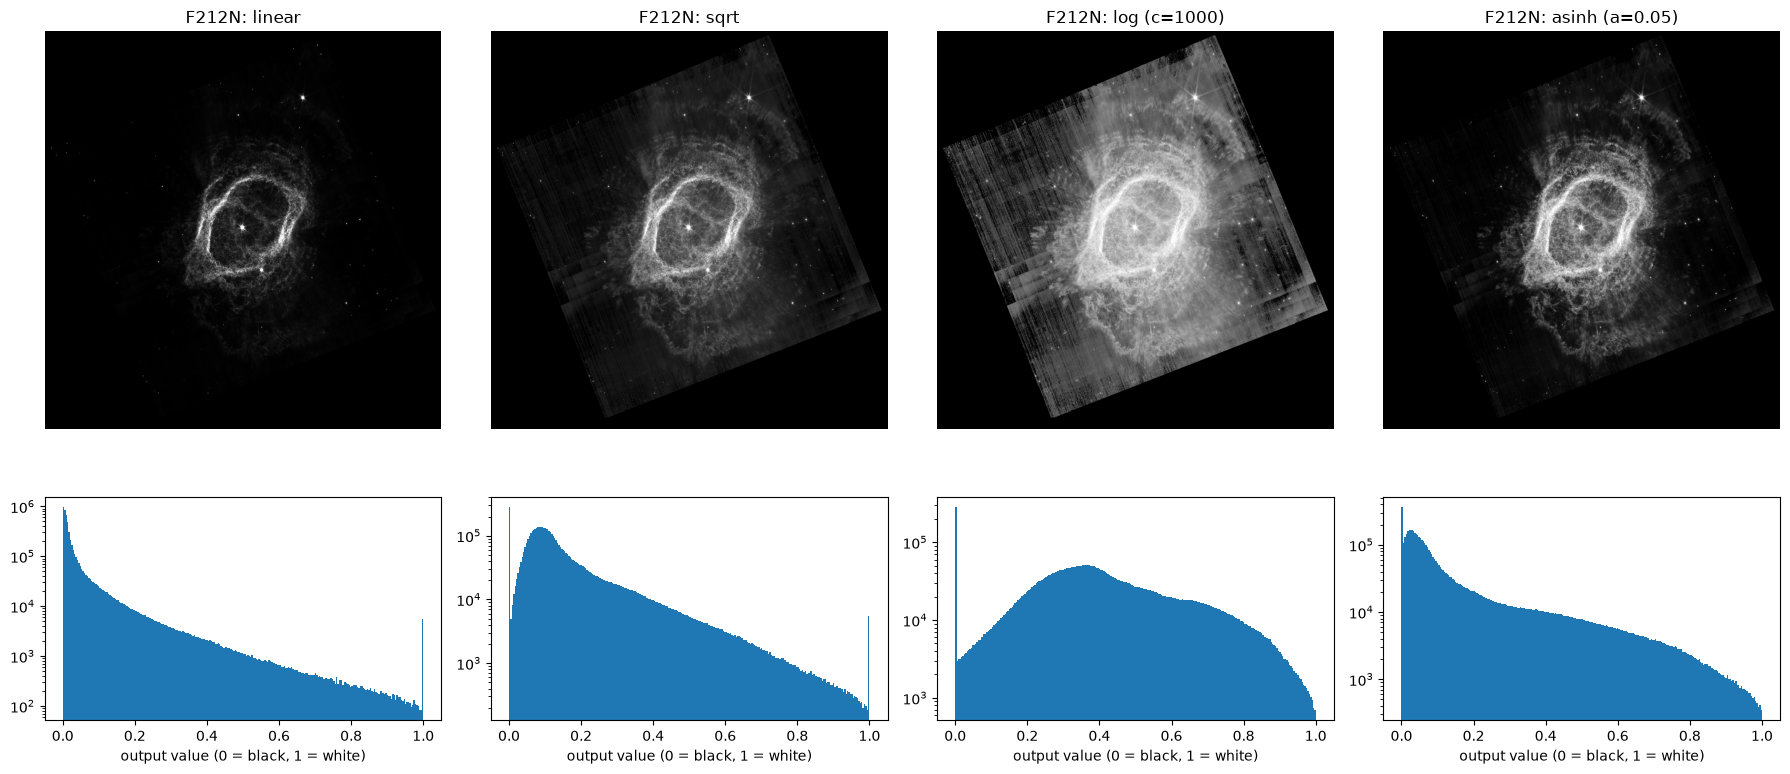

In [18]:
def normalize(img, bkg, noise, black_k, white_pct):
    x = img - bkg
    black = -black_k * noise
    white = np.percentile(x[valid], white_pct)
    y = np.clip((x - black) / (white - black), 0, 1)
    return np.where(valid, y, 0.0).astype(np.float32), float(black), float(white)

STRETCHES = {
    "linear": lambda y: y,
    "sqrt":   lambda y: np.sqrt(y),
    "log (c=1000)": lambda y: np.log10(1 + 1000 * y) / np.log10(1 + 1000),
    "asinh (a=0.05)": lambda y: np.arcsinh(y / 0.05) / np.arcsinh(1 / 0.05),
}

b = "F212N"
y0, _, _ = normalize(imgs[b], stats[b]["bkg"], stats[b]["noise"], black_k=1.0, white_pct=99.9)

fig, axes = plt.subplots(2, 4, figsize=(18, 9), gridspec_kw={"height_ratios": [3, 1]})
for i, (name, f) in enumerate(STRETCHES.items()):
    s = f(y0)
    axes[0, i].imshow(s, origin="lower", cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"{b}: {name}")
    axes[0, i].axis("off")
    axes[1, i].hist(s[valid], bins=256, range=(0, 1), log=True)
    axes[1, i].set_xlabel("output value (0 = black, 1 = white)")
plt.tight_layout()

Die Histogramme unten zeigen, **wohin die Pixel auf der Ausgabeskala fallen**: Bei linear klebt fast alles bei 0 (schwarz), bei log wird der Hintergrund weit nach oben geschoben (graues, verrauschtes Bild). Gut ist eine Verteilung, bei der der Hintergrund dunkel bleibt, der Nebel aber einen großen Teil der Skala nutzt.

### Ausschnitt: schwache Filamente

Am Rand des Nebels sieht man am besten, wie die Kurven mit Rauschen umgehen.

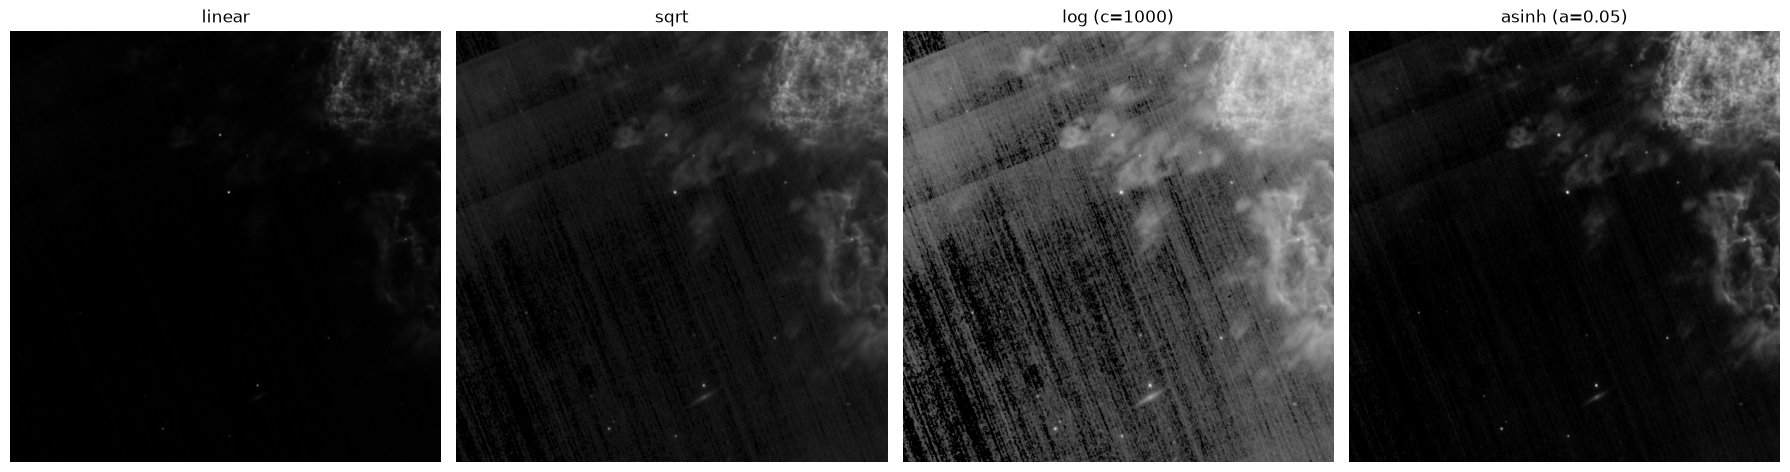

In [19]:
cy, cx = valid.shape[0] // 2, valid.shape[1] // 2
crop = np.s_[cy - 900:cy - 300, cx - 900:cx - 300]   # adjust to a faint outer region

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (name, f) in zip(axes, STRETCHES.items()):
    ax.imshow(f(y0)[crop], origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()

## 4. Parameter pro Filter festlegen

Startwerte: asinh mit `a = 0.05`, Weißpunkt 99,9 %. Schwarzpunkt `bkg − k·noise`: **größeres k → Schwarzpunkt tiefer → Hintergrund heller/rauschiger**; k = 0 → Schwarzpunkt genau auf dem Hintergrund; **negatives k → Rauschen (und schwächste Struktur) wird schwarz**. Für die Filter mit Detektor-Mustern (F187N, F212N) daher negative k.

**Hier darfst und sollst du experimentieren.** Jeder Filter wird auf seinen eigenen Weißpunkt normiert. Das heißt: Die *relativen* Helligkeiten zwischen den Filtern gehen verloren, jeder Filter nutzt die volle Skala. Das ist eine **ästhetische** Entscheidung (gleichgewichtige Kanäle für die Farbe), keine wissenschaftliche, und wird so dokumentiert.

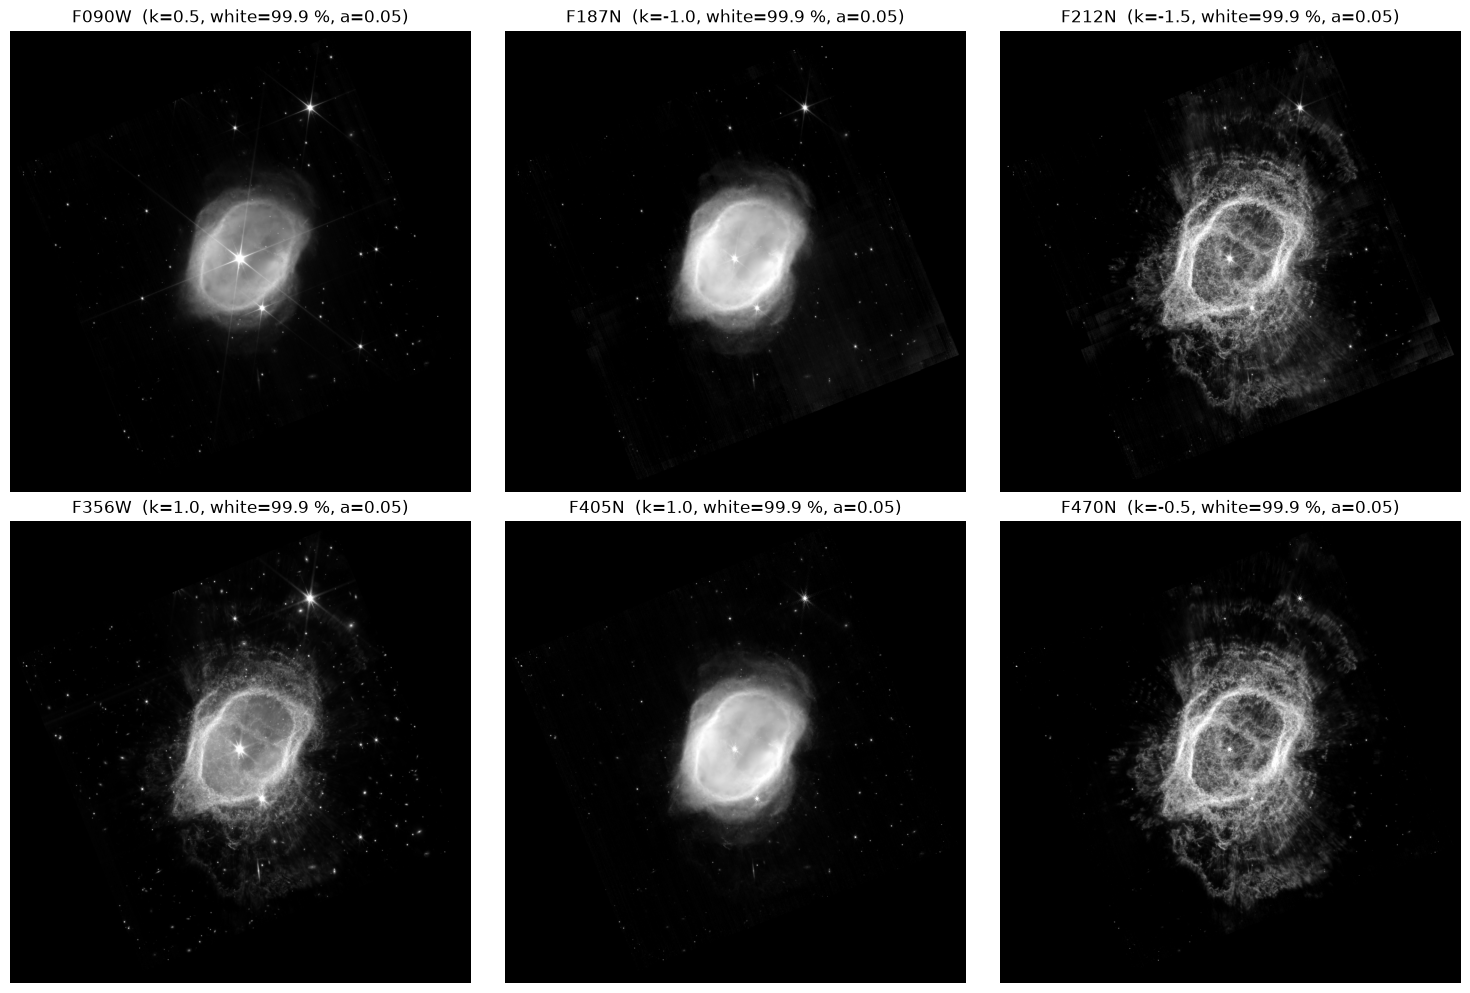

In [22]:
PARAMS = {
    "F090W": dict(black_k=0.5,  white_pct=99.9, a=0.05),
    "F187N": dict(black_k=-1.0, white_pct=99.9, a=0.05),
    "F212N": dict(black_k=-1.5, white_pct=99.9, a=0.05),
    "F356W": dict(black_k=1.0,  white_pct=99.9, a=0.05),
    "F405N": dict(black_k=1.0,  white_pct=99.9, a=0.05),
    "F470N": dict(black_k=-0.5, white_pct=99.9, a=0.05),
}

def stretch_band(b):
    p = PARAMS[b]
    y, black, white = normalize(imgs[b], stats[b]["bkg"], stats[b]["noise"], p["black_k"], p["white_pct"])
    out = np.arcsinh(y / p["a"]) / np.arcsinh(1 / p["a"])
    return out.astype(np.float32), black, white

stretched, levels = {}, {}
for b in BANDS:
    stretched[b], black, white = stretch_band(b)
    levels[b] = dict(black=black, white=white)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, b in zip(axes.flat, BANDS):
    ax.imshow(stretched[b], origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{b}  (k={PARAMS[b]['black_k']}, white={PARAMS[b]['white_pct']} %, a={PARAMS[b]['a']})")
    ax.axis("off")
plt.tight_layout()

## 5. Speichern: Bilder und Parameter

- Gestreckte Bilder (float32, 0–1) als FITS nach `data/ngc3132_nircam_stretched/` (nicht im Git), mit den Parametern im Header.
- **Alle Parameter und gemessenen Werte** als JSON nach `params/ngc3132_stretch.json`. Diese kleine Datei kommt ins Repo: Damit ist das Bild später exakt reproduzierbar und die Bearbeitung offengelegt.

In [24]:
record = {
    "input": str(IN_DIR),
    "sky_boxes": {"size_px": BOX, "edge_margin_px": EDGE_MARGIN, "yx": [list(map(int, b)) for b in boxes]},
    "saturated_holes_filled_px": filled,
    "stretch": "asinh: out = asinh(y/a)/asinh(1/a), y = clip((img - bkg - black)/(white - black), 0, 1)",
    "per_band": {b: {**PARAMS[b], **stats[b], **levels[b]} for b in BANDS},
}
PARAM_FILE.write_text(json.dumps(record, indent=2))
print("parameters ->", PARAM_FILE)

for b in BANDS:
    hdr = header.copy()
    hdr["BAND"] = b
    hdr["BUNIT"] = ("", "dimensionless, stretched 0-1")
    for k, v in record["per_band"][b].items():
        hdr[f"S_{k[:6].upper()}"] = v
    out = OUT_DIR / f"ngc3132_{b.lower()}_stretched.fits"
    fits.PrimaryHDU(data=stretched[b], header=hdr).writeto(out, overwrite=True)
    print(b, "->", out.name)

parameters -> ../params/ngc3132_stretch.json
F090W -> ngc3132_f090w_stretched.fits
F187N -> ngc3132_f187n_stretched.fits
F212N -> ngc3132_f212n_stretched.fits
F356W -> ngc3132_f356w_stretched.fits
F405N -> ngc3132_f405n_stretched.fits
F470N -> ngc3132_f470n_stretched.fits


## Fazit

- **Himmelsboxen:** Die erste Auswahl (nur „nicht überlappend“) legte alle 6 Boxen in eine Ecke und unterschätzte die Ungleichmäßigkeit. Mit Mindestabstand 500 px verteilt; überwiegend links, weil rechts der schwache H₂-Halo weiter reicht. Scores eng beieinander (0,032–0,042) → keine Box auf Nebel.
- **Rauschen in leeren Boxen** ist 4–20× kleiner als die Schätzung über das ganze Bild aus Etappe 2 → die alte Schätzung hat vor allem Nebelstruktur gemessen.
- **Ungleichmäßiger Hintergrund:** Schwankung zwischen den Boxen 2–4× das Rauschen bei F187N, F212N, F356W, F470N (Detektor-Blöcke und senkrechte Streifen, v. a. F187N/F212N). F470N hat einen gleichmäßigen Offset (≈ 0,42 MJy/sr), der einfach abgezogen wird.
- **Gesättigte Sternkerne** sind in den Daten NaN. Über die gemeinsame Gültigkeitsmaske wurden die Sterne zunächst schwarz. Lösung: Lücken *innerhalb* des Bildes (`binary_fill_holes`) mit dem Maximalwert des Filters füllen → weiß. Kosmetisch, 160–510 px pro Filter.
- **Streckungen (F212N):** linear zeigt nur Ring und Stern; log hebt die Detektor-Streifen massiv an (Hintergrund ≈ 0,35 statt schwarz); Wurzel moderat; **asinh** bester Kompromiss: Hintergrund nahe 0, Nebel nutzt die ganze Skala.
- **Schwarzpunkt `bkg − k·noise`:** größeres k → Schwarzpunkt tiefer → Hintergrund *heller*. Für F187N (k = −1), F212N (−1,5) und F470N (−0,5) negativ, um Detektor-Muster zu verstecken, auf Kosten der schwächsten Struktur. Die Muster selbst lassen sich so nicht entfernen (bekannte Einschränkung, Korrektur wäre auf Rohdatenebene nötig).
- **Ästhetische Entscheidung:** Jeder Filter wird auf seinen eigenen Weißpunkt normiert → gleichgewichtige Kanäle für die Farbmischung, aber die relativen Helligkeiten zwischen den Filtern gehen verloren.
- **Nebenfund:** kleine Galaxie, von der Kante gesehen, im Ausschnitt unterhalb des Nebels.

**Nächster Schritt:** Etappe 5 – Farben zuordnen und mischen.